# Ôn kiểm tra khóa 2

Khóa 2 nối hai việc: tự dựng và debug mạng neural ở chương 3, rồi dùng lại model đã học ở chương 4. Gặp một bài mới, điểm xuất phát không phải model lớn nhất mà là một pipeline chạy được, đo được và nộp đúng. Buổi này ôn cách ra quyết định và kiểm lỗi theo đúng thứ tự làm một bài thi: đọc đề, debug một batch, chọn cách dùng model pretrained, đọc kết quả, tải lại và ghi file nộp. Bài làm của buổi kiểm tra nằm ở mục bài tập; trang này ôn lại cả quy trình bằng một ví dụ chạy được.

> **Mục tiêu sau buổi này**
>
> - Dựng một baseline nhỏ có split, metric và file output đúng định dạng.
> - Tìm lỗi shape, loss, gradient và chế độ tầng trên một batch có thể kiểm tay.
> - Chọn giữa head-only, fine-tuning, LoRA và zero-shot bằng validation có ý nghĩa.
> - Lưu rồi tải lại checkpoint, processor và ánh xạ nhãn để tái tạo dự đoán.

## Đi từ đề đến một mốc đo được

Giả sử đề cho ảnh hoạt động của câu lạc bộ, cần xếp mỗi ảnh vào một trong ba nhóm, chấm bằng macro-F1 và nộp một hàng dự đoán cho mỗi ID. Trước hết ghi lại input, output, số lớp, metric và cách chia validation. Ảnh chụp trong cùng một buổi thường giống nhau về ánh sáng, phông nền và người xuất hiện. Nếu test gồm những buổi mới thì validation cũng phải gồm những buổi mới: chia theo buổi. Split ngẫu nhiên theo ảnh cho điểm đẹp hơn nhưng có thể chỉ đo khả năng nhận lại bối cảnh đã thấy.



**Hỏi nhanh.** Ảnh đến từ 40 buổi sinh hoạt, mỗi buổi 30 ảnh, và test là 10 buổi tổ chức sau đó. Chia ngẫu nhiên theo ảnh thì macro-F1 trên validation là 0.93, chia theo buổi thì là 0.71. Con số nào gần với điểm test hơn?

- A. 0.71, vì validation cũng gồm những buổi chưa thấy
- B. 0.93, vì validation ngẫu nhiên có đủ mọi buổi
- C. 0.93, vì hai cách chia dùng chung một kiến trúc model
- D. 0.82, vì trung bình hai cách chia cho ước lượng ổn hơn

<details><summary>Đáp án</summary>

A. 0.71, vì validation cũng gồm những buổi chưa thấy

Test là những buổi mới, nên validation phải mô phỏng buổi mới. Chia theo ảnh đặt những ảnh gần như trùng nhau của cùng một buổi vào cả train lẫn validation, và model được thưởng vì nhận lại được bối cảnh, điều không xảy ra ở test. “Có đủ mọi buổi” chính là chỗ rò rỉ. Lấy trung bình hai con số đo hai câu hỏi khác nhau thì chẳng đo được câu hỏi nào.

</details>

Tiếp theo chạy vài hàng từ đọc input đến file output. Kiểm ID không trùng, không thiếu, đúng thứ tự hoặc đúng giao thức join của đề. Chọn một baseline nhỏ: mạng tự dựng khi đề yêu cầu, feature extraction nếu có encoder phù hợp, hoặc zero-shot khi có asset tương ứng. Baseline phải chạy trong đúng môi trường chấm. Một kiến trúc dựng với trọng số ngẫu nhiên, ví dụ `resnet50(weights=None)`, chỉ là mạng chưa học: nó không mang kiến thức pretrained, dù cùng tên kiến trúc.

**Hỏi nhanh.** Máy thi không có Internet. Code gọi `resnet50(weights=None)`, freeze toàn bộ rồi train head trên 600 ảnh, và macro-F1 validation chỉ được 0.35. Nên nghi gì trước tiên?

- A. Head quá nhỏ, cần thêm hai lớp ẩn
- B. Backbone chưa học gì, chỉ là trọng số ngẫu nhiên
- C. Learning rate của head quá lớn với 600 ảnh
- D. Macro-F1 luôn thấp hơn accuracy, nên số này bình thường

<details><summary>Đáp án</summary>

B. Backbone chưa học gì, chỉ là trọng số ngẫu nhiên

`weights=None` không nạp trọng số nào, nên tham số được khởi tạo ngẫu nhiên. Freeze chúng là giữ cố định một phép biến đổi ngẫu nhiên, và head chỉ học trên đặc trưng ngẫu nhiên. Phải nạp đúng tệp trọng số được cấp, rồi kiểm bằng một phép so, chẳng hạn dự đoán của một ảnh mẫu có khớp với output đã biết không. Sửa head hay learning rate không cứu được những đặc trưng không mang thông tin.

</details>

## Debug một batch trước khi tăng ngân sách

Với classifier ba lớp, logits cần shape `(B,3)`, nhãn chỉ số lớp thường có shape `(B,)` và kiểu số nguyên cho `CrossEntropyLoss`. Loss này nhận logits, không cần gọi softmax trước. Kiểm forward cho số hữu hạn, loss có nghĩa và backward tạo gradient ở đúng phần cần học. Thử học thuộc một tập cực nhỏ có nhãn nhất quán giúp kiểm đường training; thành công trên tập nhỏ chưa chứng minh generalization.

**Hỏi nhanh.** Model ba lớp kết thúc bằng `nn.Softmax(dim=1)`, rồi đưa output vào `CrossEntropyLoss`. Thử cho học thuộc 8 mẫu: accuracy lên 1.0, nhưng loss dừng ở 0.551 và không giảm thêm. Hiểu thế nào?

- A. Learning rate quá nhỏ, loss chưa kịp về 0
- B. 8 mẫu quá ít, loss không thể thấp hơn
- C. Nhãn bị lệch nên loss không xuống thêm
- D. Softmax bị áp hai lần, nên loss có một mức sàn 0.551

<details><summary>Đáp án</summary>

D. Softmax bị áp hai lần, nên loss có một mức sàn 0.551

`CrossEntropyLoss` tự làm log-softmax. Đầu vào đã là xác suất nằm trong $[0, 1]$, nên trường hợp tốt nhất là $(1, 0, 0)$, cho loss $-\ln\frac{e}{e + 2} \approx 0.551$. Accuracy 1.0 loại trừ khả năng nhãn bị lệch. Loss đứng yên đúng ở một hằng số qua nhiều bước là dấu hiệu của mức sàn, không phải do bước nhỏ. Bỏ lớp Softmax để loss nhận logits.

</details>



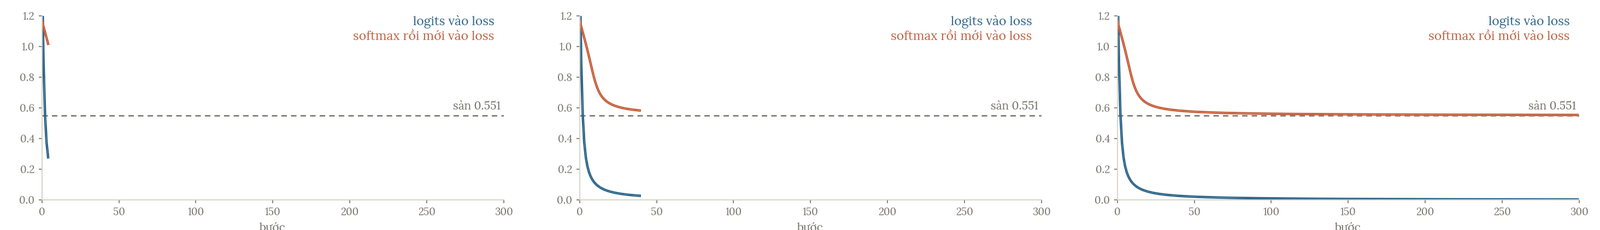

Nếu dùng head-only, so `state_dict` của encoder trước và sau vài bước optimizer: tham số phải giữ nguyên, còn buffer thì theo đúng quyết định của thí nghiệm. Với BatchNorm, freeze weight/bias chưa ngăn running mean đổi khi module ở train mode. Với LoRA, A ngẫu nhiên và B bằng 0 làm gradient của A bằng 0 ở bước đầu, còn gradient của B thường khác 0. Đó là hành vi đúng theo chain rule, không phải lỗi cần sửa.

**Hỏi nhanh.** LoRA một chiều: $y = (w_0 + ba)x$, với $w_0 = 1$ đã freeze, $a = 0.5$, $b = 0$. Mẫu có $x = 1$, target $t = 3$, loss $(y - t)^2$, SGD với learning rate 0.1. Ở bước 1, gradient của $a$ bằng 0. Ở bước 2, gradient của $a$ bằng bao nhiêu?

- A. 0
- B. $-2$
- C. $-0.76$
- D. $-1.9$

<details><summary>Đáp án</summary>

C. $-0.76$

Bước 1: $\partial L/\partial y = 2(1 - 3) = -4$, nên $\partial L/\partial a = -4\cdot b\cdot x = 0$, và $\partial L/\partial b = -4\cdot a\cdot x = -2$. Vậy $b$ lên $0.2$, còn $a$ giữ 0.5. Bước 2: $y = 1.1$, $\partial L/\partial y = -3.8$, nên $\partial L/\partial a = -3.8\cdot 0.2 = -0.76$. Gradient của $a$ chỉ bằng 0 khi $b = 0$. $-2$ và $-1.9$ là gradient của $b$ ở bước 1 và bước 2.

</details>

## Chọn bước tiếp bằng một câu hỏi

Head-only hỏi embedding có đọc được nhãn mới không. Fine-tuning hỏi cập nhật phần encoder có cải thiện validation không. LoRA hỏi nhánh sửa ít tham số có đủ chất lượng trong ngân sách không. Zero-shot hỏi kiến thức có sẵn và mô tả lớp có tạo baseline dùng được không. Mỗi thay đổi nên có lý do từ lỗi hoặc giới hạn hiện tại, rồi một phép đo so với mốc cũ trên cùng split.



**Hỏi nhanh.** Head-only cho macro-F1 0.74 trên train và 0.72 trên validation, và train thêm epoch cũng không đổi gì. Bước tiếp theo hợp lý nhất là gì?

- A. Train head thêm 50 epoch tới khi train đạt 1.0
- B. Mở block cuối hoặc thêm LoRA, rồi so trên cùng cách chia
- C. Đổi sang accuracy, vì macro-F1 khó tăng hơn
- D. Gộp validation vào train để head có thêm dữ liệu

<details><summary>Đáp án</summary>

B. Mở block cuối hoặc thêm LoRA, rồi so trên cùng cách chia

Train và validation cùng thấp, sát nhau và đã bão hòa: một head tuyến tính trên embedding cố định không tách các lớp tốt hơn được nữa. Câu hỏi tiếp theo là cập nhật một phần encoder có giúp không, nên mở block cuối hoặc thêm LoRA với learning rate nhỏ, rồi so với mốc 0.72 trên cùng cách chia. Train head lâu hơn không làm embedding tốt lên. Đổi metric hay bỏ validation thì mất luôn thước đo.

</details>

Không so các mode bằng một cột accuracy nếu metric đề là macro-F1, hoặc chỉ nhìn số tham số để kết luận tổng bộ nhớ. Ghi processor, split, model/revision, seed, batch size, precision, learning rate, phần mở, checkpoint chọn và thời gian thực đo. Giữ một bản có thể nộp trước khi thử một thay đổi tốn nhiều thời gian.

**Hỏi nhanh.** Lần chạy mới vừa mở thêm hai block, vừa tăng learning rate từ $10^{-4}$ lên $3\cdot 10^{-4}$, và macro-F1 validation tăng từ 0.72 lên 0.75. Kết luận nào có căn cứ?

- A. Mở thêm block là nguyên nhân của cải thiện
- B. Learning rate lớn hơn là nguyên nhân của cải thiện
- C. Hai thay đổi đóng góp như nhau, mỗi cái 0.015
- D. Cấu hình mới tốt hơn, nhưng chưa tách được nguyên nhân

<details><summary>Đáp án</summary>

D. Cấu hình mới tốt hơn, nhưng chưa tách được nguyên nhân

Hai thay đổi cùng lúc thì chỉ so được hai cấu hình với nhau. Muốn biết thay đổi nào có ích, phải chạy thêm một lần chỉ đổi một yếu tố, cùng cách chia và cùng seed. Chênh 0.03 trên một tập validation nhỏ cũng nên kiểm lại bằng vài seed trước khi tin.

</details>

## Đọc kết quả rồi tải lại

Khi train loss tiếp tục giảm nhưng validation loss đạt đáy rồi tăng, ta giữ checkpoint ở đáy theo tiêu chí đã chọn, rồi kiểm lại augmentation, mức mở và regularization. Validation accuracy có thể chưa giảm, vì argmax của từng mẫu chưa đổi; loss thì đã ghi nhận việc model ngày càng tự tin vào những dự đoán sai. Một mẫu sai có xác suất lớp đúng giảm từ 0.3 xuống 0.1 làm loss của riêng nó tăng từ $-\ln0.3\approx1.20$ lên $-\ln0.1\approx2.30$, trong khi accuracy giữ nguyên. Checkpoint được chọn bằng validation đã dùng thông tin validation, nên không gọi điểm ấy là test độc lập.



**Hỏi nhanh.** Từ epoch 3 tới epoch 5, validation accuracy giữ ở 0.84, validation loss tăng từ 0.41 lên 0.58, còn train loss giảm từ 0.20 xuống 0.05. Hiểu thế nào?

- A. Model ngày càng tự tin vào những mẫu sai, tức đang overfit
- B. Loss bị tính sai, vì accuracy không đổi thì loss phải đứng yên
- C. Model chưa học xong, cần train thêm tới khi accuracy tăng
- D. Validation quá khó, train loss mới là thước đo đúng

<details><summary>Đáp án</summary>

A. Model ngày càng tự tin vào những mẫu sai, tức đang overfit

Accuracy chỉ nhìn argmax, còn loss nhìn xác suất của lớp đúng. Argmax không đổi, nhưng xác suất của lớp đúng ở những mẫu bị đoán sai giảm đi, nên validation loss tăng, trong khi train loss vẫn giảm: đó là dấu hiệu overfit. Train thêm chỉ làm khoảng cách rộng ra. Hãy giữ checkpoint theo tiêu chí đã định, và thử regularization mạnh hơn hoặc mở ít hơn.

</details>

Cuối cùng tải checkpoint vào một process mới, nạp processor và bảng nhãn đã lưu, đặt chế độ suy luận, chạy vài mẫu và so với output trước khi lưu. Sau đó dự đoán toàn bộ input cần nộp, kiểm số hàng/ID/nhãn hợp lệ. Một notebook đã chạy trong session cũ có thể vẫn dựa vào biến hoặc cache chưa lưu; bước tải lại giúp phát hiện sự phụ thuộc ấy.

**Hỏi nhanh.** Trong process mới, cho vài ảnh mẫu đi qua processor và checkpoint đã lưu: logits khớp đến từng số với trước khi lưu. Vậy mà file nộp sai nhãn hàng loạt. Code dựng lại `class_names` từ `os.listdir` của thư mục ảnh. Lỗi nằm ở đâu?

- A. Trọng số nạp sai vì thiếu `strict=True`
- B. Processor chuẩn hóa ảnh khác lúc train
- C. Bảng tên lớp dựng từ `os.listdir` bị lệch thứ tự
- D. Model còn ở chế độ train, nên dropout làm đổi dự đoán

<details><summary>Đáp án</summary>

C. Bảng tên lớp dựng từ `os.listdir` bị lệch thứ tự

Logits khớp đến từng số trên cùng ảnh mẫu đã loại trừ trọng số, processor và chế độ train hay eval. Phần còn lại là bảng đổi chỉ số ra tên lớp. `os.listdir` không bảo đảm thứ tự, và có thể khác nhau giữa các máy, nên chỉ số 0 lúc train có thể ứng với một tên lớp khác lúc nộp. Hãy lưu `class_names` vào checkpoint như ví dụ dưới, rồi đọc lại từ đó. `load_state_dict` mặc định đã là `strict=True`.

</details>

## Một pipeline nhỏ có thể đối chiếu

Phần cuối của pipeline (head, metric, lưu/tải, file nộp) có thể kiểm trước khi có encoder thật. Ta thay embedding của ảnh bằng bốn vector hai chiều và đặt trọng số head bằng tay, nên mọi con số đều tính tay được. Lỗi hợp đồng bắt được ở đây không cần đến asset lớn.

Mỗi hàng là một mẫu, mỗi cột là một đặc trưng. Head có ba hàng trọng số tương ứng ba lớp. Với mẫu đầu `(2,0)`, ba logits là `2,0,-2`, nên nhãn dự đoán là 0. Mẫu cuối có nhãn thật 1 nhưng head dự đoán 0: ta cố ý giữ một lỗi để thấy accuracy và macro-F1 không trùng nhau.

In [ ]:
import io
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.metrics import accuracy_score, f1_score

torch.set_num_threads(1)
features = torch.tensor([[2., 0.], [0., 2.], [-1., -1.], [1.5, 0.]])
targets = np.array([0, 1, 2, 1])
class_names = ["nhom_A", "nhom_B", "nhom_C"]
head = nn.Linear(2, 3, bias=False)
with torch.no_grad():
    head.weight.copy_(torch.tensor([[1., 0.], [0., 1.], [-1., -1.]]))
head.eval()
with torch.inference_mode():
    logits = head(features)
    predictions = logits.argmax(dim=1).numpy()
assert logits.shape == (4, 3)
assert np.isfinite(logits.numpy()).all()
print("du doan:", predictions.tolist())
print("accuracy:", accuracy_score(targets, predictions))
print("macro-F1:", round(f1_score(targets, predictions, labels=[0, 1, 2],
                                 average="macro", zero_division=0), 6))

du doan: [0, 1, 2, 0]
accuracy: 0.75
macro-F1: 0.777778


Accuracy là $3/4$. Với lớp 0, precision là $1/2$ và recall là 1 nên F1 bằng $2/3$. Lớp 1 có precision 1 và recall $1/2$, cũng bằng $2/3$; lớp 2 có F1 bằng 1. Macro-F1 là trung bình $(2/3+2/3+1)/3=7/9$. Khi metric đề khác accuracy, không thể coi hai con số là cùng một tiêu chí.



Hình cho thấy vì sao mẫu cuối sai. Logit lớp 0 bằng $x_1$, lớp 1 bằng $x_2$, lớp 2 bằng $-x_1-x_2$; mỗi biên là nơi hai logit bằng nhau, và ba biên là ba tia đi qua gốc. Điểm $(1.5,0)$ có $x_1>x_2$ nên rơi vào vùng 0. Muốn sửa, head phải học lại trọng số từ dữ liệu; metric và file nộp chỉ phản ánh đúng những gì head làm.

**Hỏi nhanh.** Cùng target `[0, 1, 2, 1]`. Head A dự đoán `[0, 1, 2, 0]`, head B dự đoán `[0, 1, 1, 1]`. Cả hai có accuracy 0.75. Macro-F1 của head nào cao hơn?

- A. A, với 0.778, còn B chỉ 0.600
- B. B, với 0.800, còn A chỉ 0.778
- C. Bằng nhau, vì accuracy bằng nhau
- D. B, vì B đoán đúng cả hai mẫu lớp 1

<details><summary>Đáp án</summary>

A. A, với 0.778, còn B chỉ 0.600

B không dự đoán lớp 2 lần nào, nên F1 của lớp 2 bằng 0. Lớp 1 của B có precision 2/3, recall 1, F1 0.8. Lớp 0 có F1 bằng 1. Macro-F1 của B là $(1 + 0.8 + 0)/3 = 0.6$, còn của A là $7/9 \approx 0.778$. 0.8 chỉ là F1 riêng của lớp 1. Macro-F1 phạt nặng việc bỏ sót cả một lớp, điều mà accuracy không thấy.

</details>

Ta lưu trọng số cùng bảng nhãn và kích thước input, rồi dựng một đối tượng head mới. `BytesIO` đóng vai một tệp trong bộ nhớ, nên ví dụ không ghi gì ra đĩa. Trong bài thi, ghi ra tệp thật và tải lại trong một tiến trình mới như bài 3.4: phép kiểm trong cùng session không bắt được code còn dựa vào biến chưa lưu.

In [ ]:
buffer = io.BytesIO()
torch.save({"state_dict": head.state_dict(), "class_names": class_names,
            "input_dim": 2}, buffer)
buffer.seek(0)
saved = torch.load(buffer, map_location="cpu", weights_only=True)
restored = nn.Linear(saved["input_dim"], len(saved["class_names"]), bias=False)
restored.load_state_dict(saved["state_dict"])
restored.eval()
with torch.inference_mode():
    restored_logits = restored(features)
assert torch.equal(logits, restored_logits)
sample_ids = [43, 41, 42, 44]
submission = pd.DataFrame({"id": sample_ids, "label": predictions})
csv_buffer = io.StringIO()
submission.to_csv(csv_buffer, index=False)
csv_buffer.seek(0)
read_back = pd.read_csv(csv_buffer)
assert read_back["id"].tolist() == sample_ids
assert read_back["id"].is_unique and len(read_back) == len(features)
assert read_back["label"].between(0, len(class_names) - 1).all()
print("tai lai trung:", torch.equal(logits, restored_logits))
print(read_back.to_string(index=False))

tai lai trung: True
 id  label
 43      0
 41      1
 42      2
 44      0


ID 43 vẫn đứng trước 41 vì đó là thứ tự input đã cho. Hợp đồng ở đây là hai cột `id,label`; đề thật có thể yêu cầu xác suất từng lớp, tên cột khác hoặc đúng thứ tự của sample submission. Nếu judge ghép theo thứ tự hàng thay vì theo `id`, một file đúng nội dung nhưng sai thứ tự vẫn gán dự đoán cho nhầm mẫu.

**Hỏi nhanh.** Máy chấm bỏ qua cột `id`, chấm theo thứ tự hàng của file nộp mẫu `41, 42, 43, 44`, với nhãn thật lần lượt là 1, 2, 0, 1. Nộp nguyên file của ví dụ, có thứ tự `43, 41, 42, 44`, thì accuracy bằng bao nhiêu?

- A. 0.75, vì dự đoán không thay đổi
- B. 0.50, vì chỉ hai hàng đầu bị đảo
- C. 0.25, vì hàng ID 44 đúng vị trí
- D. 0, vì cả bốn hàng đều sai

<details><summary>Đáp án</summary>

D. 0, vì cả bốn hàng đều sai

Hàng đầu mang dự đoán 0 của ID 43, nhưng được chấm cho ID 41, nhãn 1. Tương tự, dự đoán 1 bị chấm cho ID 42, nhãn 2, và dự đoán 2 bị chấm cho ID 43, nhãn 0. Hàng cuối đúng vị trí, nhưng vốn đã đoán sai, 0 so với nhãn 1. Cùng nội dung mà accuracy rơi từ 0.75 xuống 0. Hãy sắp lại theo file nộp mẫu, rồi assert `id` khớp từng hàng trước khi nộp.

</details>



## Khi đi thi

- **Đọc metric và đơn vị chia trước khi viết model.** Macro-F1 hay accuracy, ảnh độc lập hay theo buổi: hai câu trả lời này quyết định checkpoint nào được giữ và validation có đáng tin không.
- **Nộp một bản sớm.** Baseline head-only hoặc zero-shot chạy hết đến file nộp hợp lệ; mọi thử nghiệm sau so với mốc này trên cùng split.
- **Kiểm asset trước khi tính giờ train.** Trọng số pretrained phải nạp được từ tệp được cấp, không cần mạng; `weights=None` chỉ là mạng ngẫu nhiên.
- **Debug một batch trước khi chạy dài.** Shape, loss hữu hạn, phần nào có gradient, phần nào nằm trong optimizer, BatchNorm đang ở chế độ nào.
- **Tải lại rồi mới nộp.** Process mới, đọc checkpoint, processor và bảng nhãn đã lưu, so vài logits, rồi assert số hàng, `id` và nhãn hợp lệ theo sample submission.

## Tóm tắt

Khóa 2 quy về một chuỗi bằng chứng. Đề được đọc thành input, output, metric và split. Một batch đi qua forward, loss, backward với đúng shape và đúng chế độ. Mỗi cách dùng model pretrained (head-only, fine-tuning, LoRA, zero-shot) trả lời một câu hỏi riêng và được so trên cùng split. Checkpoint được chọn theo tiêu chí định trước, tải lại trong tiến trình mới và cho ra file nộp đúng hợp đồng.



Trước buổi kiểm tra, chạy lại ba ví dụ: một mạng nhỏ, một bài feature extraction và một bài LoRA. Với mỗi ví dụ, viết một phép kiểm độc lập từ công thức hoặc dữ liệu nhỏ và giải thích một lỗi có thể xảy ra dù code không báo exception. Khi quên, đọc lại [bài 4.1](4.1.md) về hợp đồng asset, [4.2](4.2.md) về pooling và cache, [4.3](4.3.md) về freeze và eval, [4.4](4.4.md) về gradient và rank của LoRA, [4.5](4.5.md) về điểm zero-shot.

## Kiểm tra cuối bài

**Câu 1.** Validation có 100 ảnh: 80 ảnh nhóm A, 12 ảnh nhóm B, 8 ảnh nhóm C. Một baseline luôn đoán A. Accuracy và macro-F1 của nó bằng bao nhiêu?

- A. Accuracy 0.80, macro-F1 0.80
- B. Accuracy 0.80, macro-F1 0.89
- C. Accuracy 0.80, macro-F1 0.30
- D. Accuracy 0.33, macro-F1 0.30

<details><summary>Đáp án</summary>

C. Accuracy 0.80, macro-F1 0.30

Lớp A có precision 0.8, recall 1, nên F1 $= 2\cdot 0.8/1.8 \approx 0.889$. Lớp B và C không được đoán lần nào, nên F1 bằng 0. Macro-F1 là $0.889/3 \approx 0.30$. 0.89 là F1 riêng của lớp A. 0.80 là accuracy. 0.33 là balanced accuracy, tức trung bình các recall. Một bộ phân loại luôn đoán một lớp có recall 1 ở lớp ấy, và precision bằng tỉ lệ của lớp ấy. Với macro-F1, baseline đoán lớp đông gần như vô dụng; hãy kiểm metric trước khi tin vào điểm đầu tiên.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q5.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=21)

</details>

**Câu 2.** Một neuron $h(x) = \sigma(w_0 + w_1x)$, với $w_0 = 0$, phân loại dương khi $h(x) > 0.5$. Đổi $w_1$ từ 1 lên 2. Cái gì thay đổi?

- A. Vùng dương thu hẹp thành $x > 0.5$
- B. Vẫn là $x > 0$, nhưng đầu ra xa 0.5 hơn
- C. Vùng dương mở rộng thành $x > -0.5$
- D. Không có gì đổi, cả vùng lẫn đầu ra

<details><summary>Đáp án</summary>

B. Vẫn là $x > 0$, nhưng đầu ra xa 0.5 hơn

$h(x) > 0.5$ khi và chỉ khi $w_0 + w_1x > 0$, tức $x > 0$ với mọi $w_1 > 0$, nên ranh giới không đổi. Nhưng $h(1)$ tăng từ 0.731 lên 0.881, và $h(-1)$ giảm từ 0.269 xuống 0.119: model tự tin hơn ở cả hai phía. Accuracy giữ nguyên, còn cross-entropy thì đổi. Đây cũng là lý do validation loss có thể tăng trong khi accuracy đứng yên.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q1(b)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=2)

</details>

**Câu 3.** Mạng 10 lớp, mỗi lớp một neuron sigmoid: $o_i = \sigma(w_io_{i-1} + b_i)$, với $o_0 = x$ và mọi $w_i = 1$. Cận trên của $|\partial o_{10}/\partial w_1|$ và của $|\partial o_{10}/\partial w_{10}|$ là gì?

- A. Với $w_1$ là $|x|/4$, với $w_{10}$ là $1/4^{10}$
- B. Cả hai đều là $|x|/4^{10}$
- C. Với $w_1$ là $|x|/40$, với $w_{10}$ là $1/4$
- D. Với $w_1$ là $|x|/4^{10}$, với $w_{10}$ là $1/4$

<details><summary>Đáp án</summary>

D. Với $w_1$ là $|x|/4^{10}$, với $w_{10}$ là $1/4$

Theo chain rule, $\frac{\partial o_{10}}{\partial w_{10}} = \sigma'(s_{10})\,o_9$ với $0 < o_9 < 1$, nên không vượt quá $1/4$. Còn $\frac{\partial o_{10}}{\partial w_1} = x\,\sigma'(s_1)\prod_{i=2}^{10} w_i\sigma'(s_i)$: mỗi $\sigma' \le 1/4$ và mọi $w_i = 1$, nên không vượt quá $|x|/4^{10} \approx 9.5\times 10^{-7}|x|$. Cùng learning rate, lớp cuối vẫn học, còn lớp đầu gần như đứng yên: vanishing gradient đánh vào các lớp gần input. Đảo hai cận là nhầm chiều của backprop: gradient đi từ output về, nên lớp gần output qua ít thừa số nhất. Một cận chung cho mọi lớp là bỏ qua việc mỗi lớp đi qua số thừa số khác nhau. $|x|/40$ là cộng các thừa số thay vì nhân. ReLU, khởi tạo He và kết nối residual giữ cho tích này không co lại theo cấp số nhân.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q4.5](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=20)

</details>

**Câu 4.** Early stopping theo macro-F1 validation với patience 2, tức dừng khi 2 epoch liên tiếp không vượt mức tốt nhất. Macro-F1 theo epoch là 0.62, 0.71, 0.69, 0.66, và nếu được chạy tiếp thì epoch 5 sẽ đạt 0.73. Train dừng sau epoch nào, và giữ checkpoint nào?

- A. Dừng sau epoch 4, giữ epoch 2
- B. Dừng sau epoch 4, giữ epoch 4
- C. Dừng sau epoch 3, giữ epoch 3
- D. Chạy tới epoch 5, giữ epoch 5

<details><summary>Đáp án</summary>

A. Dừng sau epoch 4, giữ epoch 2

Epoch 2 lập mức 0.71. Epoch 3 và 4 đều thấp hơn, đủ patience 2, nên dừng sau epoch 4 và nạp lại trọng số của epoch 2, không phải trọng số cuối. Epoch 5 tốt hơn nhưng không được chạy: patience là một sự đánh đổi giữa ngân sách và rủi ro dừng quá sớm, và khi validation dao động mạnh thì nên đặt patience lớn hơn. Early stopping chống overfit bằng cách dừng lại khi validation xấu đi.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 189](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=69)

</details>

**Câu 5.** Trong process mới, nạp checkpoint rồi dự đoán cùng một ảnh hai lần, được hai vector logits khác nhau. Trọng số đã khớp với `state_dict` được lưu. Nguyên nhân khả dĩ nhất là gì?

- A. Checkpoint bị hỏng khi ghi ra đĩa
- B. Model còn ở chế độ train, dropout vẫn đang bật
- C. Chưa bọc `torch.no_grad()` nên forward bị ngẫu nhiên
- D. Processor tải lại khác phiên bản lúc train

<details><summary>Đáp án</summary>

B. Model còn ở chế độ train, dropout vẫn đang bật

Module mới dựng mặc định ở chế độ train, và `model.train()` hay `model.eval()` đổi cách dropout và BatchNorm hoạt động. Dropout tắt ngẫu nhiên các neuron ở mỗi lần forward, nên cùng một input cho ra kết quả khác nhau. Hãy gọi `model.eval()` trước khi dự đoán. `no_grad` chỉ tắt việc ghi graph, không đổi kết quả forward. Checkpoint hỏng hay processor khác thì sai lệch phải lặp lại giống nhau giữa hai lần chạy, chứ không dao động.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 124](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=48)

</details>

**Câu 6.** Linear attention cần một ánh xạ hữu hạn chiều $\phi$ sao cho $\phi(q)^\top\phi(k) \approx \exp(q^\top k)$, với hệ số $1/\sqrt d$ đã gộp vào $q$, $k$. Dùng Taylor bậc hai $\exp(x) \approx 1 + x + x^2/2$ và $(q^\top k)^2 = \sum_{a,b} q_aq_bk_ak_b$, ta lấy $\phi(q)$ gồm số 1, $d$ thành phần $q_a$, và $d^2$ tích $q_aq_b/\sqrt2$. Với $d = 64$, $\phi$ có bao nhiêu chiều $\ell$, và khi nào chi phí $O(T\ell d)$ thấp hơn $O(T^2d)$ của attention chuẩn?

- A. $\ell = 129$, khi $T > 129$
- B. $\ell = 4161$, với mọi $T$, vì chi phí tuyến tính theo $T$
- C. $\ell = 4161$, khi $T > 4161$
- D. $\ell = 65$, khi $T > 65$

<details><summary>Đáp án</summary>

C. $\ell = 4161$, khi $T > 4161$

$\phi(q)^\top\phi(k) = 1 + \sum_a q_ak_a + \tfrac12\sum_{a,b} q_aq_bk_ak_b = 1 + x + x^2/2$ với $x = q^\top k$, nên $\ell = 1 + d + d^2 = 1 + 64 + 4096 = 4161$. So $T\ell d$ với $T^2d$ thì linear attention rẻ hơn khi $T > \ell$, tức chuỗi dài hơn khoảng bốn nghìn token. 129 là chỉ giữ $d$ bình phương $q_a^2$, nhưng $\sum_a q_a^2k_a^2 \ne (q^\top k)^2$ vì thiếu các tích chéo. 65 là chỉ giữ Taylor bậc một. “Mọi $T$” là bỏ qua hằng số $\ell$: tuyến tính theo $T$ chỉ thắng khi $T$ đủ lớn. Xấp xỉ càng sát $\exp$ thì $\ell$ càng lớn; biểu diễn đúng $\exp$ thì cần $\ell$ vô hạn, như bài 3.9 đã nói.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.1.6](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=4)

</details>

**Câu 7.** Adam có hai nhóm tham số: head với learning rate $10^{-3}$, block cuối của encoder với $10^{-5}$. Ở bước đầu tiên, Adam có sửa độ lệch và $\varepsilon$ không đáng kể. Một trọng số của head có gradient 0.002, một trọng số của block có gradient 3.0. Mỗi trọng số thay đổi khoảng bao nhiêu?

- A. Head khoảng $10^{-3}$, block khoảng $10^{-5}$
- B. Head khoảng $2\cdot 10^{-6}$, block khoảng $3\cdot 10^{-5}$
- C. Head khoảng $10^{-3}$, block khoảng $10^{-3}$
- D. Head khoảng $10^{-3}$, block khoảng $3\cdot 10^{-5}$

<details><summary>Đáp án</summary>

A. Head khoảng $10^{-3}$, block khoảng $10^{-5}$

Ở bước đầu, $\hat m_1 = g$ và $\hat v_1 = g^2$, nên bước bằng $\eta\,g/|g|$: mỗi trọng số dịch đúng $\eta$ ngược dấu gradient, không phụ thuộc độ lớn của gradient. Vì vậy đặt learning rate riêng cho từng nhóm là cách trực tiếp để encoder pretrained đi bước nhỏ hơn head mới. $\eta g$ là bước của SGD. Quên tách nhóm thì cả hai dùng chung một learning rate.

</details>

**Câu 8.** Encoder 12 lớp, mỗi lớp có hai ma trận chiếu $768\times 768$, là query và value, được gắn LoRA rank 8, không có bias. Tổng số tham số adapter là bao nhiêu?

- A. 147 456
- B. 589 824
- C. 14 155 776
- D. 294 912

<details><summary>Đáp án</summary>

D. 294 912

Mỗi ma trận cần $r(d_{in} + d_{out}) = 8\cdot 1536 = 12\,288$ tham số, và có $12\cdot 2 = 24$ ma trận, nên tổng là $294\,912$. 147 456 là chỉ đếm một ma trận mỗi lớp. 589 824 là kết quả của rank 16. 14 155 776 là số tham số của chính 24 ma trận gốc, $24\cdot 768^2$, gấp 48 lần adapter. Head phân loại học thêm thì phải cộng riêng.

</details>

**Câu 9.** Zero-shot ghép nhiều template: lớp “xe đạp” lấy trung bình của hai text embedding đã chuẩn hóa, $(0.8, 0.6)$ và $(0.8, -0.6)$. Lớp “ô tô” dùng một template, $(0.6, 0.8)$. Ảnh có embedding $(0.96, 0.28)$, dài 1. Ảnh được gán vào lớp nào nếu quên chuẩn hóa vector trung bình, và nếu chuẩn hóa lại?

- A. Xe đạp ở cả hai cách, vì lấy trung bình vẫn giữ hướng
- B. Ô tô khi quên chuẩn hóa, xe đạp khi chuẩn hóa lại
- C. Xe đạp khi quên chuẩn hóa, ô tô khi chuẩn hóa lại
- D. Ô tô ở cả hai cách, vì cosine với ô tô là 0.80

<details><summary>Đáp án</summary>

B. Ô tô khi quên chuẩn hóa, xe đạp khi chuẩn hóa lại

Vector trung bình là $(0.8, 0)$, đúng hướng $(1, 0)$ nhưng chỉ dài 0.8. Quên chuẩn hóa thì điểm của xe đạp là $0.96\cdot 0.8 = 0.768$, của ô tô là $0.96\cdot 0.6 + 0.28\cdot 0.8 = 0.80$, nên ô tô thắng. Chuẩn hóa lại thành $(1, 0)$ thì điểm của xe đạp là cosine thật, $0.96 > 0.80$. Tích vô hướng chỉ bằng cosine khi cả hai vector dài 1. Các template của một lớp càng khác nhau thì vector trung bình càng ngắn, nên lớp ghép nhiều template bị thiệt một cách có hệ thống. Giữ hướng là chưa đủ, vì độ dài vẫn đi vào điểm. 0.80 không phải cosine lớn nhất, vì cosine với vector xe đạp là 0.96. Thiếu chuẩn hóa chỉ kéo điểm của xe đạp xuống, nên không thể có chuyện xe đạp thắng khi quên chuẩn hóa mà lại thua khi chuẩn hóa.

</details>

**Câu 10.** Còn 25 phút. Bản head-only, validation 0.72, đã được nộp. Fine-tune block cuối vừa cho validation 0.76 trong notebook. Lưu, tải lại ở process mới và so vài logits mất 4 phút; dự đoán toàn bộ test mất 6 phút. Nên làm gì?

- A. Train thêm 15 phút cho validation tăng rồi mới nộp
- B. Nộp ngay dự đoán từ biến trong notebook cho kịp
- C. Lưu, tải lại, dự đoán test, kiểm file rồi nộp
- D. Lấy trung bình logits của hai model rồi nộp luôn

<details><summary>Đáp án</summary>

C. Lưu, tải lại, dự đoán test, kiểm file rồi nộp

Quy trình an toàn cần khoảng 10 phút, vẫn còn dư thời gian để sửa nếu bước kiểm phát hiện lỗi, và bản head-only đã nộp là phương án dự phòng. Train thêm 15 phút thì chỉ còn đúng 10 phút, không còn chỗ cho bất kỳ lỗi nào. Dự đoán từ biến trong notebook là bỏ qua bước kiểm tải lại, đúng chỗ mà các lỗi bảng nhãn, chế độ eval hay processor lọt qua. Lấy trung bình logits là một cấu hình mới, chưa được đo trên validation.

</details>

## Đọc thêm

- [PyTorch — saving and loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html): ôn checkpoint, optimizer state và bước tải lại.
- [PyTorch — transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html): ôn một vòng train/validation đúng chế độ.
- [Recipe thực hành của chương](recipes/README.md): cách chuẩn bị asset để chạy offline, ghi license và chạy thí nghiệm văn bản, zero-shot với model thật.